# U.S. GDP growth at risk

Sebastian Jaramillo

How well did quarterly GDP forecasts describe downside risk? This notebook reconstructs the scorecard from individual forecasts. It uses the frozen study through 2026Q1. Growth is the change in 100 times log real GDP over the stated horizon.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, display
from gdp_risk.study import score_table
root = next(p for p in (Path.cwd(), *Path.cwd().parents, Path.cwd()/'project5') if (p/'results/gibbs_checks.csv').is_file())
res = root/'results'
forecasts = pd.read_csv(res/'forecasts.csv')
display(pd.read_csv(root/'data/release_calendar.csv').iloc[[0, -3, -2, -1]])
display(json.loads((res/'run.json').read_text())['inputs'])

,quarter,issue_date,release_label
0,2003Q4,2004-01-30,Advance
87,2025Q3,2025-12-23,Initial
88,2025Q4,2026-02-20,Advance
89,2026Q1,2026-04-30,Advance


{'GDPC1': '2b949b886e26c571d736763f4b730976c909e2b99eed513183f503ce8d55fc04',
 'T10Y2Y': '84b1acf52995d10513963afaf4c3bb7f622c2675ba1928c3fb97c71ed112f1b0',
 'release_calendar': 'b37a44047bc1a51d7ca817fdd4e821b7e57d25004281d681f8b6df7a67f5c036'}

## Mean accuracy and downside loss

Forecasts start with GDP through 2003Q4. For each model and horizon the scoring routine uses realized targets in the same revised snapshot. The 5% loss puts 19 times as much weight on a shortfall below the threshold as on an equally large outcome above it.

In [2]:
scores = score_table(forecasts)
pd.testing.assert_frame_equal(scores, pd.read_csv(res/'scores.csv'), atol=1e-11)
display(scores.query('sample == "full"').round(4))

,sample,model,horizon,training,n,rmse,coverage,width,breaches,breach_rate,loss05
0,full,AR,1,observed,89,1.8004,0.8989,2.3653,6,0.0674,0.1855
1,full,AR,4,observed,86,3.2966,0.8721,5.9558,8,0.0930,0.4192
2,full,ARDL,1,observed,89,1.8178,0.8989,2.4181,5,0.0562,0.1852
3,full,Drift,1,observed,89,1.3389,0.9101,2.3325,7,0.0787,0.1921
4,full,Drift,4,observed,86,2.3062,0.8721,4.6433,10,0.1163,0.4573


## Where did the annual risk forecasts miss?

The figure aligns each forecast with the quarter in which the full year of GDP growth was realized. The table isolates the outcomes below the forecast fifth percentile.

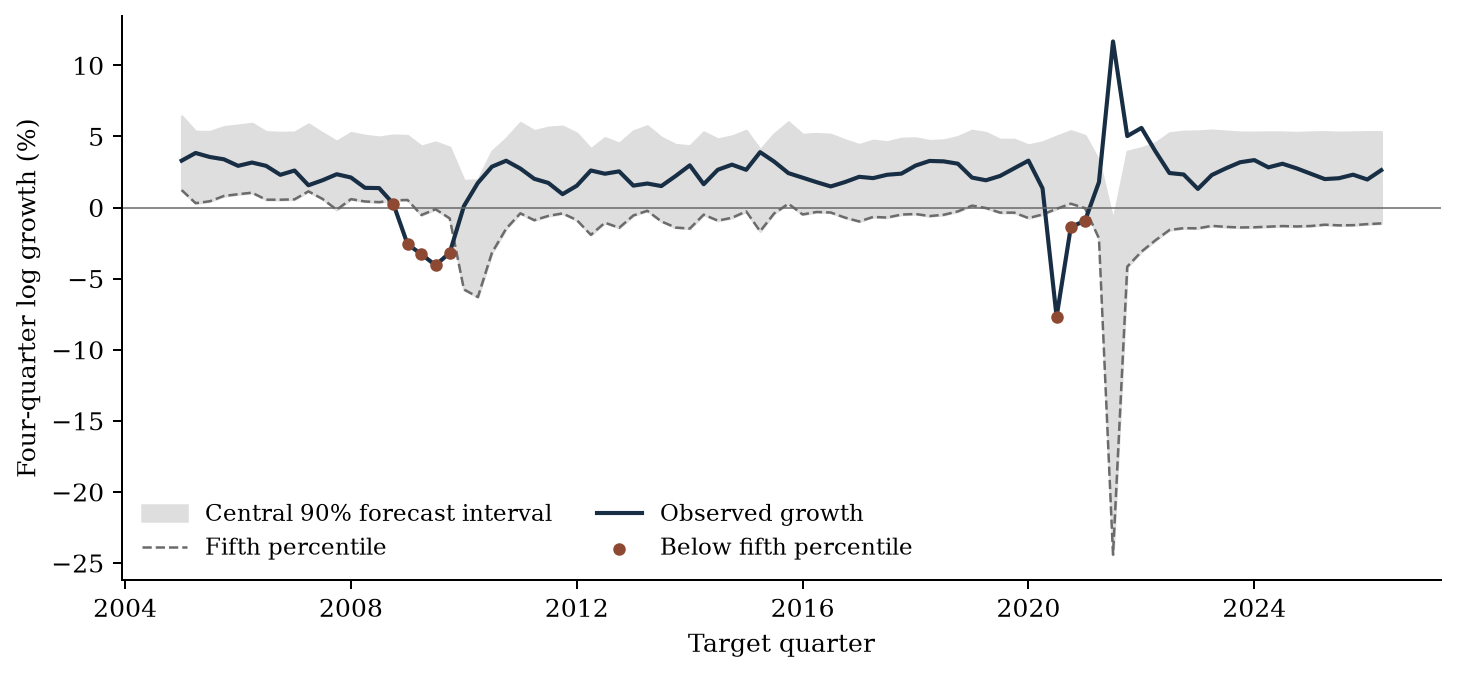

,origin,issue_date,target,actual,p05
78,2007Q3,2007-10-31,2008Q3,0.266,0.503
83,2007Q4,2008-01-30,2008Q4,-2.574,0.532
88,2008Q1,2008-04-30,2009Q1,-3.288,-0.528
93,2008Q2,2008-07-31,2009Q2,-4.060,-0.120
98,2008Q3,2008-10-30,2009Q3,-3.183,-0.763
313,2019Q2,2019-07-26,2020Q2,-7.687,-0.089
318,2019Q3,2019-10-30,2020Q3,-1.374,0.269
323,2019Q4,2020-01-30,2020Q4,-0.926,-0.045


,origin,target,mean,actual
333,2020Q2,2021Q2,-11.501031,11.676625


Largest contribution to total squared error: 57.5%


In [3]:
annual = forecasts.query('model == "AR" and horizon == 4 and training == "observed"').dropna(subset=['actual']).copy()
display(Image(filename=str(res/'figures/historical_risk.png'), width=740))
display(annual.loc[annual.actual < annual.p05, ['origin','issue_date','target','actual','p05']].round(3))
squared = (annual['mean'] - annual.actual)**2
display(annual.loc[[squared.idxmax()],['origin','target','mean','actual']])
print(f'Largest contribution to total squared error: {squared.max()/squared.sum():.1%}')

## How sensitive are the rankings to overlapping annual outcomes?

Each phase retains every fourth origin. The sample within each phase contains 21 or 22 annual outcomes.

In [4]:
display(scores[scores['sample'].str.startswith('phase')].pivot(index='sample', columns='model', values=['rmse','loss05','n']).round(3))

rmse        loss05            n      
model       AR  Drift     AR  Drift    AR Drift
sample                                         
phase_0  1.903  1.784  0.324  0.369  22.0  22.0
phase_1  1.819  1.624  0.277  0.291  22.0  22.0
phase_2  5.757  3.479  0.742  0.737  21.0  21.0
phase_3  2.027  1.892  0.346  0.444  21.0  21.0

## How did the pandemic affect the forecast distribution?

The interpolation uses an endpoint in 2022Q1. Compare both training treatments only after that endpoint entered the information set. All targets use observed GDP.

,sample,model,horizon,training,n,rmse,coverage,width,breaches,breach_rate,loss05
5,post_endpoint,AR,1,interpolated,16,0.424,1.0,1.671,0,0.0,0.043
6,post_endpoint,AR,1,observed,16,0.381,1.0,3.540,0,0.0,0.094
7,post_endpoint,AR,4,interpolated,13,0.625,1.0,4.814,0,0.0,0.138
8,post_endpoint,AR,4,observed,13,0.732,1.0,6.604,0,0.0,0.193


,origin,issue_date,target,model,training,mean,p05,p95,p_negative
0,2026Q1,2026-04-30,2026Q2,Drift,observed,0.645,-1.076,2.366,0.268
1,2026Q1,2026-04-30,2027Q1,Drift,observed,2.581,-0.892,6.055,0.110
2,2026Q1,2026-04-30,2026Q2,AR,observed,0.523,-1.203,2.248,0.308
3,2026Q1,2026-04-30,2027Q1,AR,observed,2.044,-1.150,5.225,0.144
4,2026Q1,2026-04-30,2026Q2,ARDL,observed,0.504,-1.229,2.237,0.316
5,2026Q1,2026-04-30,2026Q2,Drift,interpolated,0.646,-0.244,1.536,0.116
6,2026Q1,2026-04-30,2027Q1,Drift,interpolated,2.585,0.788,4.381,0.009
7,2026Q1,2026-04-30,2026Q2,AR,interpolated,0.443,-0.391,1.277,0.190
8,2026Q1,2026-04-30,2027Q1,AR,interpolated,1.989,-0.342,4.309,0.080
9,2026Q1,2026-04-30,2026Q2,ARDL,interpolated,0.429,-0.411,1.269,0.200


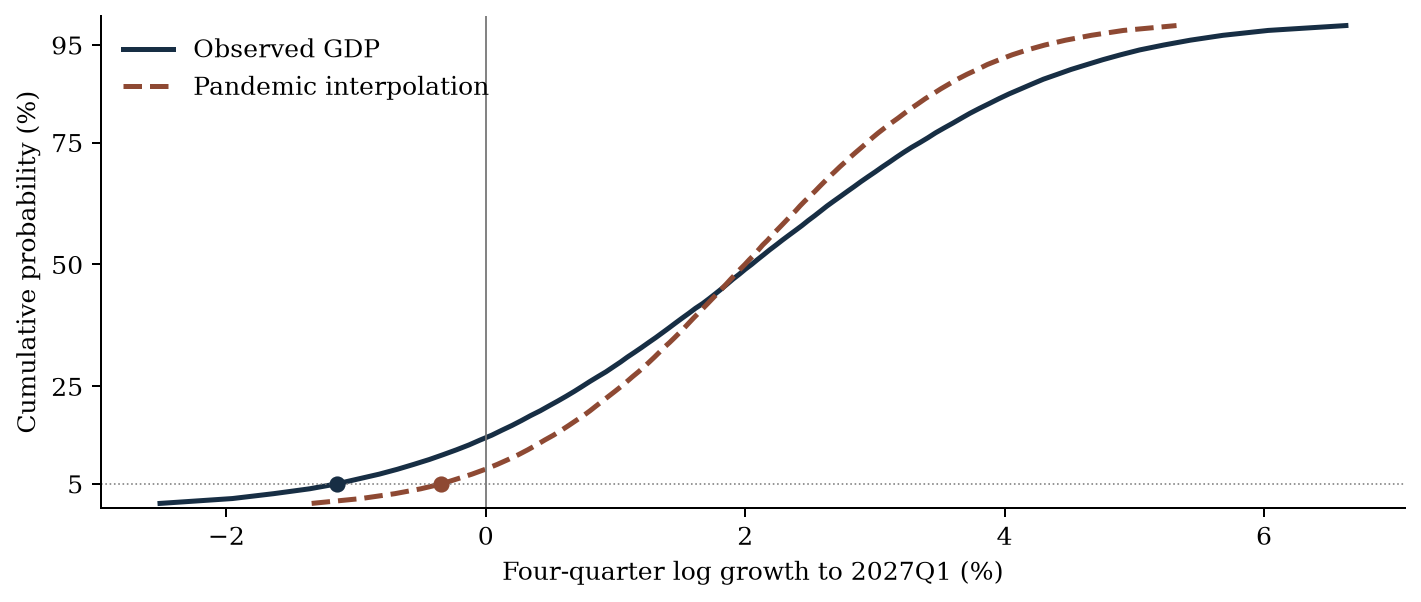

In [5]:
display(scores.query('sample == "post_endpoint" and model == "AR"').round(3))
display(pd.read_csv(res/'reference.csv')[['origin','issue_date','target','model','training','mean','p05','p95','p_negative']].round(3))
display(Image(filename=str(res/'figures/reference_distribution.png'),width=720))

## Check the numerical uncertainty

For the fixed origin, Gibbs chains and a second set of recursive paths check the main percentiles. Compare the simulation error of each estimate with the dispersion of macroeconomic outcomes.

In [6]:
checks = pd.read_csv(res/'gibbs_checks.csv')
display(checks.round(5))
assert checks.max_rhat.max() <= 1.01
assert checks[['min_bulk_ess','min_tail_ess']].min().min() >= 400

,training,model,horizon,max_rhat,min_bulk_ess,min_tail_ess,gibbs_mean,gibbs_p05,batch_se,delta_p05
0,observed,Drift,1,1.00003,30686.83564,31701.65415,0.64918,-1.07140,0.01093,0.00434
1,observed,Drift,4,1.00003,30686.83564,31701.65415,2.56634,-0.92619,0.01912,-0.03450
2,observed,AR,1,1.00014,29137.37905,30596.53543,0.52369,-1.21541,0.01397,-0.01256
3,observed,AR,4,1.00014,29137.37905,30596.53543,2.04639,-1.17297,0.02621,-0.02297
4,observed,ARDL,1,1.00040,29132.00786,30654.63420,0.50610,-1.23659,0.01099,-0.00732
5,interpolated,Drift,1,1.00003,30686.98770,31701.62767,0.64812,-0.24167,0.00565,0.00225
6,interpolated,Drift,4,1.00003,30686.98770,31701.62767,2.57677,0.77077,0.00989,-0.01767
7,interpolated,AR,1,1.00011,29236.60230,30741.07370,0.44324,-0.39635,0.00640,-0.00541
8,interpolated,AR,4,1.00011,29236.60230,30741.07370,1.99200,-0.33113,0.01612,0.01084
9,interpolated,ARDL,1,1.00040,28968.11078,30868.41707,0.43008,-0.41278,0.00469,-0.00157


The two GDP snapshots used for training in the pandemic comparison lead to different estimates of downside risk. Historical release dates establish forecast timing, while GDP revisions restrict the interpretation of historical performance. [Forecast protocol](../docs/protocol.md) · [Methods and data](../docs/methods.md) · [Research report](../docs/gdp_growth_at_risk.pdf).